Start by loading the `tidymodels` package...

In [1]:
library('tidymodels')

── Attaching packages ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels 1.4.1 ──
✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
── Conflicts ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   mask

Let's work with [hotel bookings data](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md) from TidyTuesday. 

In [2]:
hotels = 
  readr::read_csv("https://tidymodels.org/start/case-study/hotels.csv", col_types = readr::cols()) |>
  mutate(across(where(is.character), as.factor)) # turns all categorical columns into factors

hotels |> head()

  hotel        lead_time stays_in_weekend_nights stays_in_week_nights adults
1 City_Hotel   217       1                       3                    2     
2 City_Hotel     2       0                       1                    2     
3 Resort_Hotel  95       2                       5                    2     
4 Resort_Hotel 143       2                       6                    2     
5 Resort_Hotel 136       1                       4                    2     
6 City_Hotel    67       2                       2                    2     
  children meal country market_segment distribution_channel ⋯
1 none     BB   DEU     Offline_TA/TO  TA/TO                ⋯
2 none     BB   PRT     Direct         Direct               ⋯
3 none     BB   GBR     Online_TA      TA/TO                ⋯
4 none     HB   ROU     Online_TA      TA/TO                ⋯
5 none     HB   PRT     Direct         Direct               ⋯
6 none     SC   GBR     Online_TA      TA/TO                ⋯
  reserved_room_type assign

Each row is a "stay" and we want to predict whether the stay included children given the other features.

We'll want to extract a bit more information from the `arrival_date` column. So, let's make a `recipe`.

In [3]:
rec = recipe(children ~ ., data = hotels) |>
    step_date(arrival_date) |>
    step_holiday(arrival_date) |>
    step_rm(arrival_date) |>
    prep()

What does this recipe do? Look at the transformed data with "juice".

In [4]:
juice(rec) |> glimpse()

Rows: 50,000
Columns: 28
$ hotel                          <fct> City_Hotel, City_Hotel, Resort_Hotel, R…
$ lead_time                      <dbl> 217, 2, 95, 143, 136, 67, 47, 56, 80, 6…
$ stays_in_weekend_nights        <dbl> 1, 0, 2, 2, 1, 2, 0, 0, 0, 2, 1, 0, 1, …
$ stays_in_week_nights           <dbl> 3, 1, 5, 6, 4, 2, 2, 3, 4, 2, 2, 1, 2, …
$ adults                         <dbl> 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 1, 2, …
$ meal                           <fct> BB, BB, BB, HB, HB, SC, BB, BB, BB, BB,…
$ country                        <fct> DEU, PRT, GBR, ROU, PRT, GBR, ESP, ESP,…
$ market_segment                 <fct> Offline_TA/TO, Direct, Online_TA, Onlin…
$ distribution_channel           <fct> TA/TO, Direct, TA/TO, TA/TO, Direct, TA…
$ is_repeated_guest              <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …
$ previous_cancellations         <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …
$ previous_bookings_not_canceled <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, …
$ reserved_room

Let's start with a decision tree. 

In [5]:
mod = decision_tree() |>
    set_engine('rpart') |>
    set_mode('classification')

Fit `mod` using the data from your prepped recipe. (Hint: remember `juice`).

In [6]:
mod_fit = mod |> fit(children ~ ., data = juice(rec))
mod_fit

parsnip model object

n= 50000 

node), split, n, loss, yval, (yprob)
      * denotes terminal node

 1) root 50000 4038 none (0.08076000 0.91924000)  
   2) reserved_room_type=C,F,G,H 2850 1205 children (0.57719298 0.42280702)  
     4) average_daily_rate>=130.025 1879  581 children (0.69079297 0.30920703)  
       8) market_segment=Groups,Offline_TA/TO,Online_TA 1253  286 children (0.77174781 0.22825219) *
       9) market_segment=Corporate,Direct 626  295 children (0.52875399 0.47124601)  
        18) assigned_room_type=B,C,G,H,K 375  120 children (0.68000000 0.32000000) *
        19) assigned_room_type=A,E,F,I 251   76 none (0.30278884 0.69721116) *
     5) average_daily_rate< 130.025 971  347 none (0.35736354 0.64263646)  
      10) reserved_room_type=C,G,H 554  251 children (0.54693141 0.45306859)  
        20) adults>=1.5 502  201 children (0.59960159 0.40039841) *
        21) adults< 1.5 52    2 none (0.03846154 0.96153846) *
      11) reserved_room_type=F 417   44 none (0.1055

Use the snippet below to visualize the tree. What is the first split?

```r
rpart.plot::rpart.plot(mod_fit$fit)
```

Warning message:
“Cannot retrieve the data used to build the model (so cannot determine roundint and is.binary for the variables).
To silence this warning:
    Call rpart.plot with roundint=FALSE,
    or rebuild the rpart model with model=TRUE.”


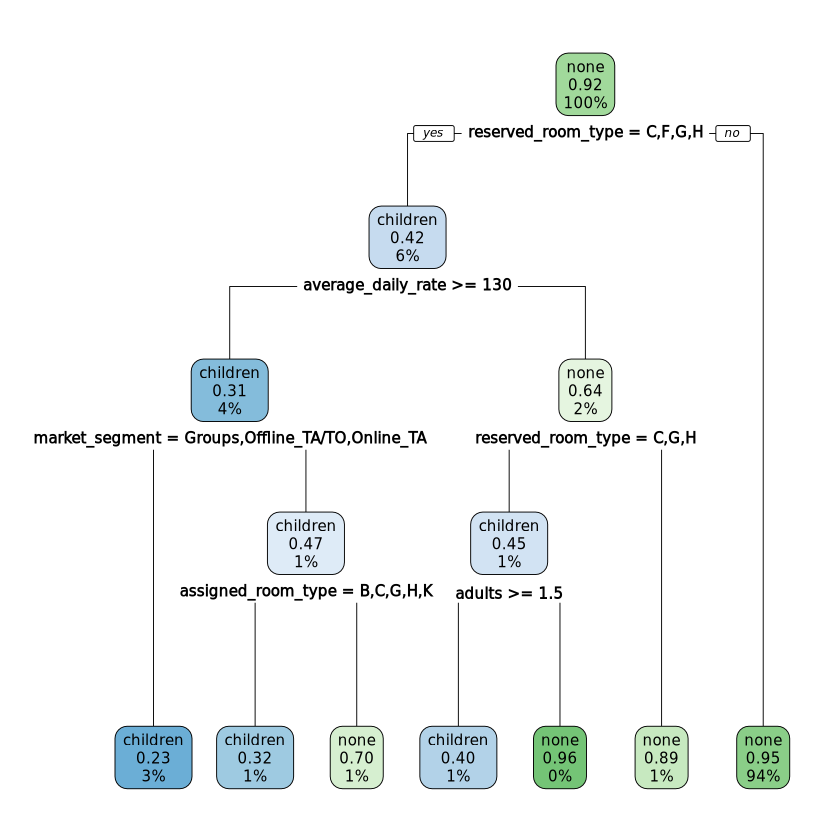

In [7]:
rpart.plot::rpart.plot(mod_fit$fit)

Now create a `rand_forest` model and fit it to the transformed `hotels` data.

1. the `mode` should be "classification", and,
2. add `importance = "impurity"` to `set_engine` so we can calculate feature importances with the model.

In [8]:
rf_mod = rand_forest() |>
    set_engine('ranger', importance = 'impurity') |>
    set_mode('classification')

rf_fit = rf_mod |> fit(children ~ ., data = juice(rec))
rf_fit

parsnip model object

Ranger result

Call:
 ranger::ranger(x = maybe_data_frame(x), y = y, importance = "impurity",      num.threads = 1, verbose = FALSE, seed = sample.int(10^5,          1), probability = TRUE) 

Type:                             Probability estimation 
Number of trees:                  500 
Sample size:                      50000 
Number of independent variables:  27 
Mtry:                             5 
Target node size:                 10 
Variable importance mode:         impurity 
Splitrule:                        gini 
OOB prediction error (Brier s.):  0.04207752 

We can plot the feature importances. Pipe your fitted model into `extract_fit_engine()` and then into `vip(num_features = 20)`.

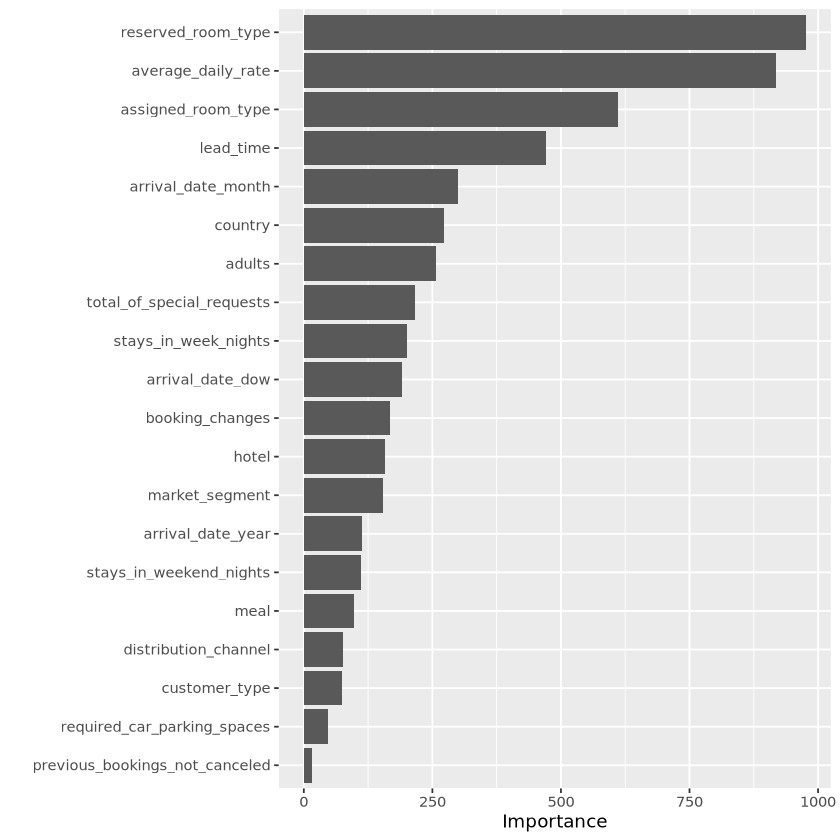

In [11]:
library('vip')

rf_fit |>
    extract_fit_engine() |>
    vip(num_features = 20)